# Final project
## Imports

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import math
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score


## Data
All data is collected into the data folder. I am using some files from the course BERN01. The files that I use from BERN01 are the following:

**Climate files** There are five climate variables which are daily average values during 1961-1990. These are:
 - Tswrf (Total shortwave radiation flux, W m-2), 
 - Pre (Precipitation, mm day-1), 
 - Tmp (Daily mean temperature, K), 
 - Tmax (Daily maximum temperature, K)
 - Tmin (Daily minimum temperature, K). 

**LPJ-GUESS_output_BERN1.csv** This file contains the following variables:
 - NPP: net primary productivity (kg C m-2 year-1)
 - SoilR: soil respiration (kg C m-2 year-1)
 - MaxBiomeCmass: The maximum biomass from a single biome (kg C m-2)
 - MxbiomeLAI: The maximum leaf area index from a single biome (unitless)
 - VegC: Vegetation carbon poo (kg C m-2)l
 - LitterC: Litter carbon pool (kg C m-2)
 - SoilC: Soil carbon pool (kg C m-2)
 - Biome_Cmass: The biome type based on the maximum biomass (category)
 - Biome_LAI: The biome type based on the maximum LAI (category)
 - Biome_obs: The observed biome type (category)

**soilmap.dat**  This file contains texture information for each grid cell (Percentage). 

**gridlist_pan_gfed_ISO3_UN_ecoregion.txt** This file contains gridded data for countries, ecoregions, regions used by 
GFED (Global Fire emissions database) and carbon sink studes (Pan et al., 2011: doi:10.1126/science.1201609)

In addition, I am also using data from The Northern Circumpolar Soil Carbon Database (NCSCD). These are:

**NCSCDv2_Circumpolar_netCDF_05deg/NCSCDv2_Circumpolar_WGS84_nonsoil_pct_05deg.nc** which contains percentages of non soil contents in the Northern circumpolar region. 

**NCSCDv2_Circumpolar_netCDF_05deg/NCSCDv2_Circumpolar_WGS84_SOCC100_05deg.nc** which contains amount of soil organic carbon (SOC) in the upper 100 cm soil layer in the Northern circumpolar region. 

### Load data

In [2]:
LAT_LON = ["Lat", "Lon"]

# LPJ-GUESS 
lpj_df = pd.read_csv("data/LPJ-GUESS_output_BERN1.csv")
lpj_df = lpj_df.rename(columns={col: col + f"_lpj" for col in lpj_df.columns if not col in LAT_LON})

# Grid information
grid_df = pd.read_csv("data/gridlist_pan_gfed_ISO3_UN_ecoregion.txt", sep=' ')
grid_df = grid_df.rename(columns={col: col + f"_grid" for col in grid_df.columns if not col in LAT_LON})

# Soil texture
soil_df = pd.read_csv("data/soilmap.dat", sep="\t")
soil_df = soil_df.dropna().rename(columns={"lon": "Lon", "lat": "Lat"})
soil_df = soil_df.rename(columns={col: col + f"_soil" for col in soil_df.columns if not col in LAT_LON})

# Load all climate statistics datafiles and put in one dictionary
stats_files = {
    "tswrf": "Tswrfdaymean1961_1990_stats.csv",
    "pre": "Predaymean1961_1990_stats.csv",
    "tmp": "Tmpdaymean1961_1990_stats.csv",
    "tmax": "Tmaxdaymean1961_1990_stats.csv",
    "tmin": "Tmindaymean1961_1990_stats.csv"}

stats_df = {}
for name, path in stats_files.items():
    df = pd.read_csv("data/" + path)
    df = df.rename(columns={col: col + f"_{name}" for col in df.columns if not col in LAT_LON})
    stats_df[name] = df

# Load all climate datafiles and put in one dictionary
climate_files = {
    "tswrf": "Tswrfdaymean1961_1990.csv",
    "pre": "Predaymean1961_1990.csv",
    "tmp": "Tmpdaymean1961_1990.csv",
    "tmax": "Tmaxdaymean1961_1990.csv",
    "tmin": "Tmindaymean1961_1990.csv"
}

climate_df = {}
for name, path in climate_files.items():
    df = pd.read_csv("data/" + path)
    climate_df[name] = df

# NCSCD Non-soil coverage data
nonsoil_ds = xr.open_dataset("./data/NCSCDv2_Circumpolar_netCDF_05deg/NCSCDv2_Circumpolar_WGS84_nonsoil_pct_05deg.nc")

# NCSCD Soil organic carbon data
soc_ds = xr.open_dataset("./data/NCSCDv2_Circumpolar_netCDF_05deg/NCSCDv2_Circumpolar_WGS84_SOCC100_05deg.nc")

### Data wrangling

#### Create climate concatenated info
In this section, I concatenate the climate data into a few values that should, hopefully, capture the most important metrics about the climate in different geographic locations. The metrics that I create are the following: 
 - AnnualMeanTmp_con: Annual mean temperature
 - ExtremeRangeTmp_con: The difference between the lowest temperature and the highest temperature over all years
 - AnnualTotalTswrf_con: Annual total shortwave radiation flux
 - AnnualTotalPre_con: Annual total precipitation
 - ExtremePre_con: The difference between the lowest measured precipitation and the highest measured precipitation over all years

In [35]:
# Identify daily columns
day_cols = [f"Day{i}" for i in range(1, 366)]

# Calculate annual mean temperature
tmp = climate_df["tmp"]
temperature_df = tmp[LAT_LON].copy()
temperature_df["AnnualMeanTmp_con"] = tmp[day_cols].mean(axis=1)

# Calculate annual extreme temperature range
tmax = climate_df["tmax"]
tmin = climate_df["tmin"]
temperature_df["ExtremeRangeTmp_con"] = tmax[day_cols].max(axis=1) - tmin[day_cols].min(axis=1)

# Calculate average amount of freezing degree days per year
day_cols = [c for c in tmax.columns if c.startswith("Day")]
temperature_df["FreezingDays_con"] = (tmax[day_cols] <= 273.15).sum(axis=1) # data is in Kelvin

# Calculate annual mean total solar radiation
tswrf = climate_df["tswrf"]

radiation_df = tswrf[LAT_LON].copy()
radiation_df["AnnualMeanTswrf_con"] = tswrf[day_cols].mean(axis=1) # Not used
radiation_df["AnnualTotalTswrf_con"] = tswrf[day_cols].sum(axis=1)

# Calculate annual precipitation features
pre = climate_df["pre"]

precipitation_df = pre[LAT_LON].copy()
precipitation_df["AnnualMeanPre_con"] = pre[day_cols].mean(axis=1) # Not used
precipitation_df["AnnualTotalPre_con"] = pre[day_cols].sum(axis=1)
precipitation_df["ExtremePre_con"] = pre[day_cols].max(axis=1)

#### Merge dataframes
Here, I merge all dataframes on Lon and Lat.

In [36]:
# Combine lpj_df with soil organic carbon (SOC) values from NCSCD
lpj_df = lpj_df[lpj_df["Lat"].between(soc_ds["lat"].min().item(), soc_ds["lat"].max().item())].copy() # Keep LPJ cells within the NCSCD latitude range
lpj_coords = xr.Dataset({"lon": ("obs", lpj_df["Lon"].values), "lat": ("obs", lpj_df["Lat"].values)}) # Match the remaining LPJ coordinates to the nearest NCSCD grid cells
matched_soc = soc_ds["NCSCDv2"].sel(lon=lpj_coords.lon, lat=lpj_coords.lat, method="nearest") # Find the nearest NCSCD cell for every LPJ cell
lpj_df["NCSCD_SOCC100"] = matched_soc.values # Add the SOC values to the dataframe

# Combine lpj_df with non-soil coverage values from NCSCDv2
lpj_df = lpj_df[lpj_df["Lat"].between(nonsoil_ds["lat"].min().item(), nonsoil_ds["lat"].max().item())].copy()  # Keep LPJ cells within the non-soil latitude range
lpj_coords = xr.Dataset({"lon": ("obs", lpj_df["Lon"].values), "lat": ("obs", lpj_df["Lat"].values)})  # Match LPJ coordinates to NCSCD grid cells
matched_nonsoil = nonsoil_ds["NCSCDv2"].sel(lon=lpj_coords.lon, lat=lpj_coords.lat, method="nearest")  # Find the nearest non-soil coverage cell for every LPJ cell
lpj_df["NCSCD_nonsoil_pct"] = matched_nonsoil.values  # Add non-soil coverage (%) to the dataframe

# Add soil and grid info
merged_df = lpj_df.merge(grid_df, on=LAT_LON, how="inner").merge(soil_df, on=LAT_LON, how="inner") 

# Add climate statistics
for name, df in stats_df.items(): 
    merged_df = merged_df.merge(df, on=LAT_LON, how="inner")

# Add my own temperature statistics
merged_df = merged_df.merge(temperature_df, on=LAT_LON, how="inner" )
merged_df = merged_df.merge(radiation_df, on=["Lon", "Lat"], how="left")
merged_df = merged_df.merge(precipitation_df, on=["Lon", "Lat"], how="left")

#merged_df.head()
print(merged_df.columns.tolist())

['Lon', 'Lat', 'NPP_lpj', 'SoilR_lpj', 'MaxBiomeCmax_lpj', 'MaxBiomeLAI_lpj', 'VegC_lpj', 'LitterC_lpj', 'SoilC_lpj', 'Biome_Cmax_lpj', 'Biome_LAI_lpj', 'Biome_obs_lpj', 'NCSCD_SOCC100', 'NCSCD_nonsoil_pct', 'GFED-region_grid', 'Pan_2007_grid', 'ISO3_grid', 'UN_grid', 'Ecoregion_grid', 'clay_soil', 'silt_soil', 'sand_soil', 'orgC_soil', 'CN_soil', 'pH_soil', 'cellfraction_soil', 'SpringMean_tswrf', 'SpringMedian_tswrf', 'SpringStd_tswrf', 'SummerMean_tswrf', 'SummerMedian_tswrf', 'SummerStd_tswrf', 'FallMean_tswrf', 'FallMedian_tswrf', 'FallStd_tswrf', 'WinterMean_tswrf', 'WinterMedian_tswrf', 'WinterStd_tswrf', 'SpringMean_pre', 'SpringMedian_pre', 'SpringStd_pre', 'SummerMean_pre', 'SummerMedian_pre', 'SummerStd_pre', 'FallMean_pre', 'FallMedian_pre', 'FallStd_pre', 'WinterMean_pre', 'WinterMedian_pre', 'WinterStd_pre', 'SpringMean_tmp', 'SpringMedian_tmp', 'SpringStd_tmp', 'SummerMean_tmp', 'SummerMedian_tmp', 'SummerStd_tmp', 'FallMean_tmp', 'FallMedian_tmp', 'FallStd_tmp', 'Winter

### Add weights to each row 
Since I have access to nonsoil percentages, I will use this as a filter to add weights to the different locations in the dataset. This will give observations with a higher percentage of soil more impact on the training of the neural network. 

In [45]:
weights = 1 - merged_df["NCSCD_nonsoil_pct"] / 100 # if 20 % if non-soil, the weight is 0,8
merged_df["weights"] = weights

## Investigate data

In [6]:
# Look at the nonsoil data variable
nonsoil = nonsoil_ds["NCSCDv2"]
print(nonsoil.to_dataframe().describe())

# count the number of non-NaN values in the dataset
non_nan_count = np.count_nonzero(~np.isnan(nonsoil.values))
print("\nNumber of non-NaN values:", non_nan_count)
print("Total number of values:", nonsoil.size)
print("Percentage of non-NaN values:", (non_nan_count / nonsoil.size) * 100, "%")

# Look at the latitude and longitude values
print("\n", nonsoil_ds.lat.values[:10])
print(nonsoil_ds.lon.values[:10])
print("Lat spacing:", np.diff(nonsoil_ds.lat.values[:10]))
print("Lon spacing:", np.diff(nonsoil_ds.lon.values[:10]))

            NCSCDv2
count  17947.000000
mean      27.268736
std       37.387192
min        0.000000
25%        0.000000
50%        5.000000
75%       41.000000
max      100.000000

Number of non-NaN values: 17947
Total number of values: 79920
Percentage of non-NaN values: 22.456206206206204 %

 [89.75 89.25 88.75 88.25 87.75 87.25 86.75 86.25 85.75 85.25]
[-179.75 -179.25 -178.75 -178.25 -177.75 -177.25 -176.75 -176.25 -175.75
 -175.25]
Lat spacing: [-0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5]
Lon spacing: [0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5]


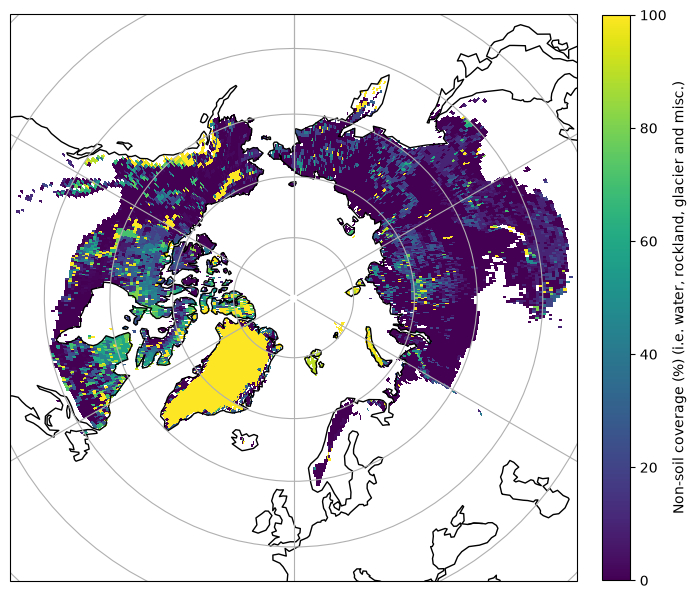

In [7]:
nonsoil = nonsoil_ds["NCSCDv2"]
cmap = plt.cm.viridis.copy()
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(8,8), subplot_kw={"projection": ccrs.NorthPolarStereo()})
nonsoil.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, x="lon", y="lat", add_colorbar=True,
             cbar_kwargs={"shrink": 1, "fraction": 0.0456, "pad": 0.04,
                          "label": "Non-soil coverage (%) (i.e. water, rockland, glacier and misc.)"})
ax.set_extent([-180, 180, 45, 90], crs=ccrs.PlateCarree())
ax.coastlines()
ax.gridlines()
ax.set_title("")
plt.show()

In [8]:
# Look at the Soil Organic Carbon data
soc = soc_ds["NCSCDv2"]
soc_df = soc.to_dataframe()
print(soc_df.describe())

# count the number of non-NaN values in the dataset
non_nan_count_soc = np.count_nonzero(~np.isnan(soc.values))
print("\nNumber of non-NaN values:", non_nan_count_soc)
print("Total number of values:", soc.size)
print("Percentage of non-NaN values:", (non_nan_count_soc / soc.size)*100, "%")

            NCSCDv2
count  17904.000000
mean     200.756195
std      165.194794
min        0.000000
25%       60.000000
50%      178.000000
75%      320.250000
max     1228.000000

Number of non-NaN values: 17904
Total number of values: 79920
Percentage of non-NaN values: 22.4024024024024 %


/Users/andrearaaschou/courses/BERN02/.venv/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:301: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)


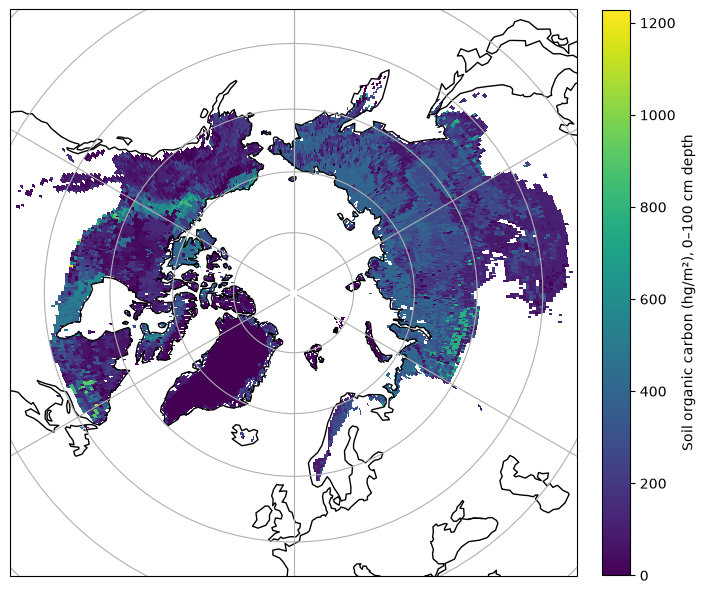

In [9]:
# Plot soil organic carbon content
cmap = plt.cm.viridis.copy()
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(8,8), subplot_kw={"projection": ccrs.NorthPolarStereo()})
soc.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, x="lon", y="lat", add_colorbar=True,
         cbar_kwargs={"shrink": 1, "fraction": 0.0456, "pad": 0.04,
                      "label": "Soil organic carbon (hg/m²), 0–100 cm depth"})
ax.set_extent([-180, 180, 45, 90], crs=ccrs.PlateCarree())
ax.coastlines()
ax.gridlines()
ax.set_title("")
plt.show()

### Alignment between nonsoil data and SOC data

In [10]:
# Check for alignment between nan values in nonsoil coverage and soc
small_df = merged_df[["Lon", "Lat", "NCSCD_SOCC100", "NCSCD_nonsoil_pct"]]
mismatch = small_df["NCSCD_SOCC100"].isna() != small_df["NCSCD_nonsoil_pct"].isna()
small_df[mismatch].head(10)
print("Number of mismatched occurances between NaN values:", small_df[mismatch].shape[0], "\n") #72

only_nonsoil_nan = small_df["NCSCD_SOCC100"].notna() & small_df["NCSCD_nonsoil_pct"].isna()
print(small_df[only_nonsoil_nan])
print("\nNumber of occurances where SOC has a value and nonsoil is NaN:", small_df[only_nonsoil_nan].shape[0]) #21

Number of mismatched occurances between NaN values: 72 

          Lon    Lat  NCSCD_SOCC100  NCSCD_nonsoil_pct
2576   141.75  58.75            0.0                NaN
3402   -92.75  72.75          255.0                NaN
3660   -74.75  50.25          254.0                NaN
5092   -64.75  65.25          103.0                NaN
8226  -110.75  56.25          453.0                NaN
8269   -99.25  79.75          293.0                NaN
8639   -88.75  78.25           42.0                NaN
8907    59.25  61.25           67.0                NaN
9435  -118.75  72.75          377.0                NaN
12127   77.75  67.75          260.0                NaN
14252 -178.75  66.25          211.0                NaN
15380   76.25  59.75          364.0                NaN
15451  -93.75  76.25          394.0                NaN
15644  163.25  60.75          384.0                NaN
17646   99.75  76.25          402.0                NaN
20077  -19.75  64.75          254.0                NaN
22399  -

/Users/andrearaaschou/courses/BERN02/.venv/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:301: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)


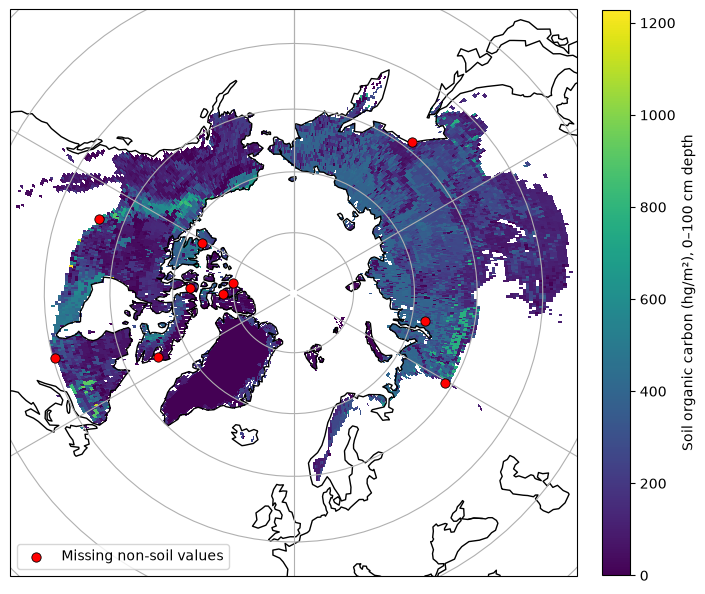

In [11]:
# Plot the 21 occurances where SOC has a value and nonsoil is NaN
nonsoil = nonsoil_ds["NCSCDv2"]
cmap = plt.cm.viridis.copy()
cmap.set_bad("white")

# Coordinates where SOC exists but non-soil coverage is NaN
missing_lon = [141.75, -92.75, -74.75, -64.75, -110.75, -99.25, -88.75, 59.25, -118.75, 77.75]
missing_lat = [58.75, 72.75, 50.25, 65.25, 56.25, 79.75, 78.25, 61.25, 72.75, 67.75]

fig, ax = plt.subplots(figsize=(8,8), subplot_kw={"projection": ccrs.NorthPolarStereo()})
soc.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, x="lon", y="lat", add_colorbar=True,
             cbar_kwargs={"shrink": 1, "fraction": 0.0456, "pad": 0.04,
                          "label": "Soil organic carbon (hg/m²), 0–100 cm depth"})

ax.scatter(missing_lon, missing_lat, transform=ccrs.PlateCarree(), color="red",
           marker="o", s=45, edgecolor="black", linewidth=0.6, label="Missing non-soil values", zorder=10)

ax.set_extent([-180, 180, 45, 90], crs=ccrs.PlateCarree())
ax.coastlines()
ax.gridlines()
ax.set_title("")
ax.legend(loc="lower left")
plt.show()

Conclusion: the missing non-soil values lie on the edges of land and sea. Ok to remove these rows.
### Alignment between NCSCD data and BERN01 data

In [12]:
print(merged_df[["Lon", "Lat", "SoilC_lpj", "NCSCD_SOCC100"]].head(10))
print("\nTotal LPJ cells:", len(merged_df))
print("NCSCD values:", merged_df["NCSCD_SOCC100"].notna().sum())
print("Percentage with NCSCD:", merged_df["NCSCD_SOCC100"].notna().mean() * 100)

      Lon    Lat  SoilC_lpj  NCSCD_SOCC100
0  166.25  60.25     29.138            NaN
1  -65.25  50.75     27.382            NaN
2   90.75  36.75      0.282            NaN
3  178.75  65.75     17.307          402.0
4  155.75  64.75     25.261          384.0
5   71.75  67.75     26.257          308.0
6   24.25  51.75     16.046            NaN
7 -102.75  63.25     13.338          209.0
8  -97.25  39.25      6.069            NaN
9 -111.75  71.25      0.037          474.0

Total LPJ cells: 26523
NCSCD values: 13138
Percentage with NCSCD: 49.53436639897448


In [13]:
# Check for alignment between the two dataframes (lon and lat values)
matched_lon = soc.sel(lon=lpj_coords.lon, method="nearest").lon.values
matched_lat = soc.sel(lat=lpj_coords.lat, method="nearest").lat.values
lon_diff = np.abs(lpj_df["Lon"].values - matched_lon)
lat_diff = np.abs(lpj_df["Lat"].values - matched_lat)
print("Grid alignment check:")
print("Max longitude difference:", lon_diff.max())
print("Max latitude difference:", lat_diff.max())
print("Mean longitude difference:", lon_diff.mean())
print("Mean latitude difference:", lat_diff.mean())

Grid alignment check:
Max longitude difference: 0.005198384072059525
Max latitude difference: 0.0020860709467598326
Mean longitude difference: 0.005198384072059525
Mean latitude difference: 0.0020860709467598326


### Randomly sample 10 NaN values to check if they are sea or land

In [14]:
sampled_rows = lpj_df[lpj_df["NCSCD_SOCC100"].isna()].sample(n=10, random_state = 2)
print(sampled_rows[["Lon", "Lat", "NCSCD_SOCC100"]])

          Lon    Lat  NCSCD_SOCC100
9655    68.75  50.25            NaN
38307 -124.25  42.75            NaN
34066   29.25  49.25            NaN
5946  -104.75  41.25            NaN
29557  132.25  46.75            NaN
35759   72.75  57.25            NaN
29866 -106.25  47.25            NaN
22419   26.75  63.75            NaN
10260   78.75  49.25            NaN
29237   36.25  41.25            NaN


Coordinates:

 - 37°15'00.0"N 6°15'00.0"W - close to sea but on land
 - 40°45'00.0"N 2°15'00.0"W - on land near Madrid
 - 41°15'00.0"N 89°15'00.0"E - on land in China
 - 39°15'00.0"N 79°45'00.0"E - on land also in China
 - 36°15'00.0"N 51°15'00.0"E - on land in Iran

My conclusion after looking at these locations and the plots of the NCSCD data is that the dataset contains Lon and Lat values that exceed the northern circumpolar region. The locations that are not within the Northern circumpolar region or are not on land are NaN in the dataframe. Therefore, I conclude that it is ok to completely discard the rows with NaN values.

### Visualize parameters

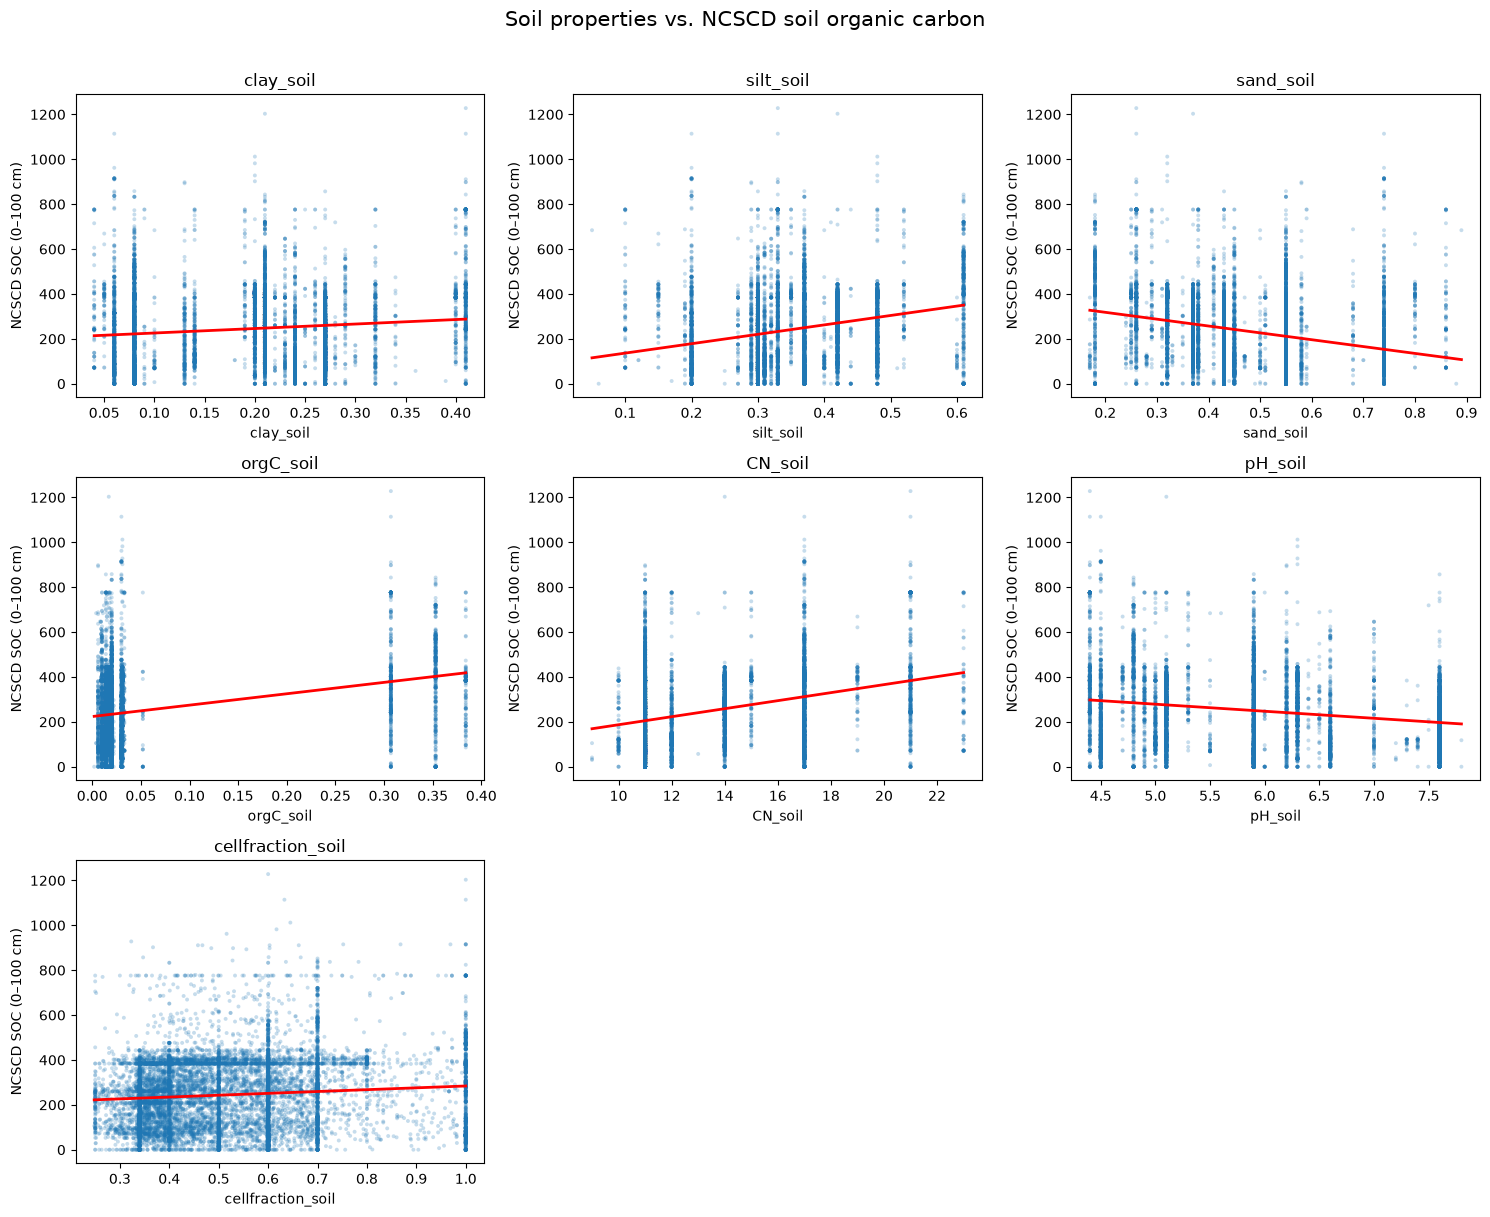

In [15]:
soil_features = [col for col in merged_df.columns if col.endswith("_soil")]
ncols = 3
nrows = math.ceil(len(soil_features) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).flatten()

for ax, feature in zip(axes, soil_features):
    data = merged_df[[feature, "NCSCD_SOCC100"]].dropna()
    x, y = data[feature], data["NCSCD_SOCC100"]
    ax.scatter(x, y, alpha=0.25, s=8, edgecolors="none")
    if len(data) > 1 and x.nunique() > 1:
        m, b = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        ax.plot(x_line, m * x_line + b, linewidth=2, color = "red")
    ax.set(title=feature, xlabel=feature, ylabel="NCSCD SOC (0–100 cm)")

for ax in axes[len(soil_features):]:
    ax.set_visible(False)

fig.suptitle("Soil properties vs. NCSCD soil organic carbon", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

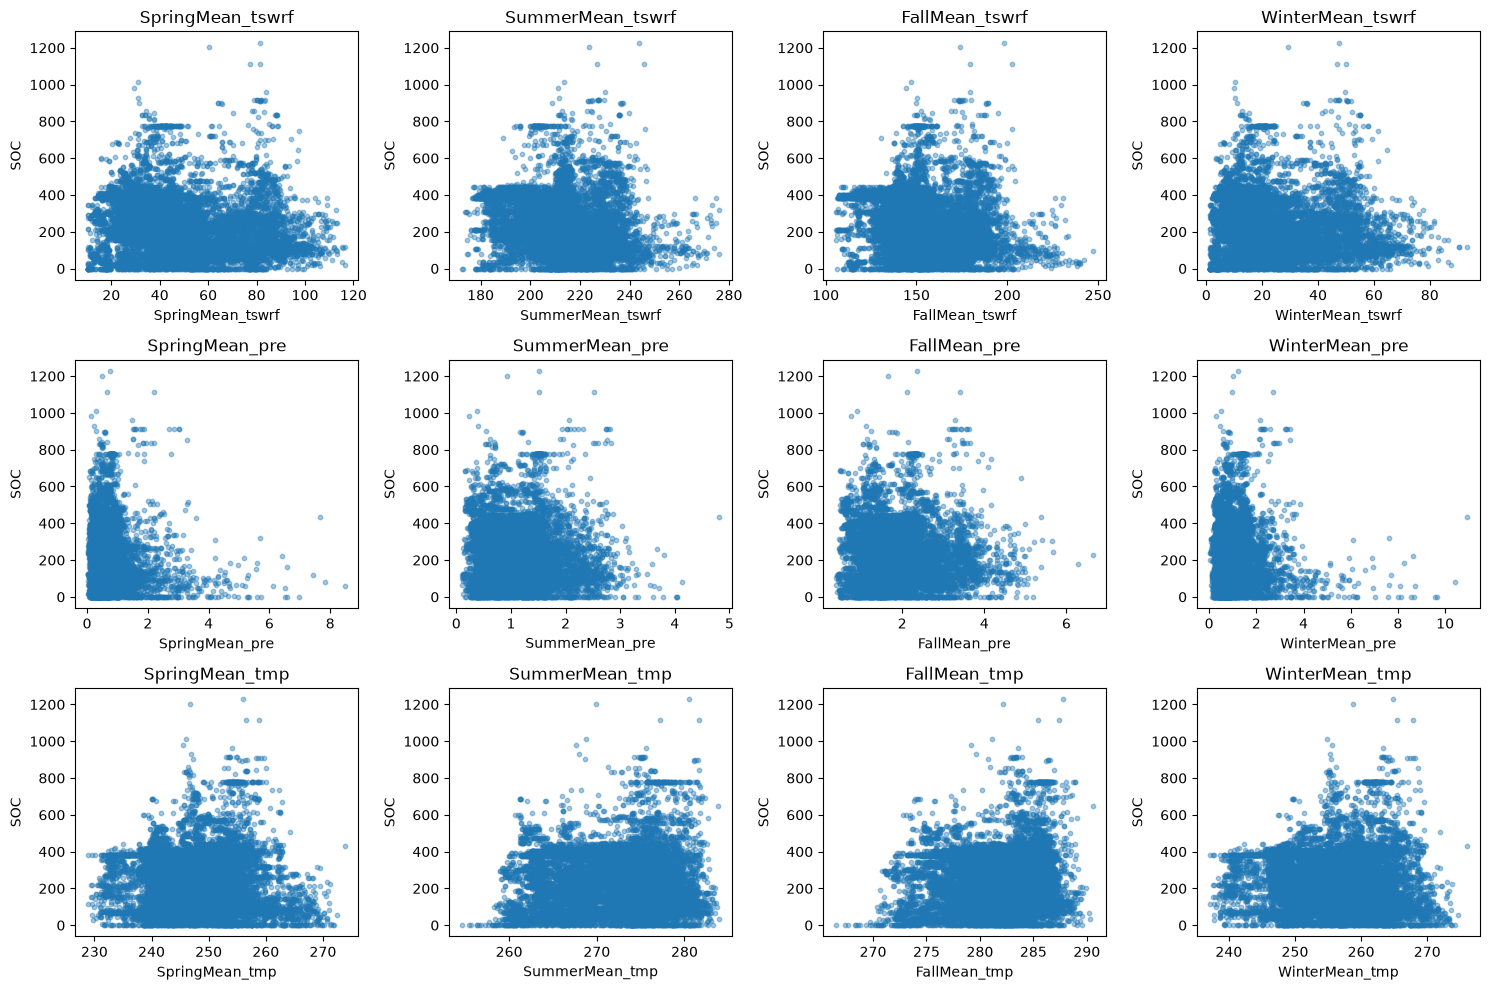

In [16]:
plot_cols = [col for col in merged_df.columns if any(f"Mean_{var}" in col for var in ["tmp", "pre", "tswrf"])]

fig, axes = plt.subplots(3, (len(plot_cols) + 2) // 3, figsize=(15, 10))
for ax, col in zip(axes.flat, plot_cols):
    ax.scatter(merged_df[col], merged_df['NCSCD_SOCC100'], alpha=0.4, s=10)
    ax.set(xlabel=col, ylabel="SOC", title=col)
for ax in axes.flat[len(plot_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

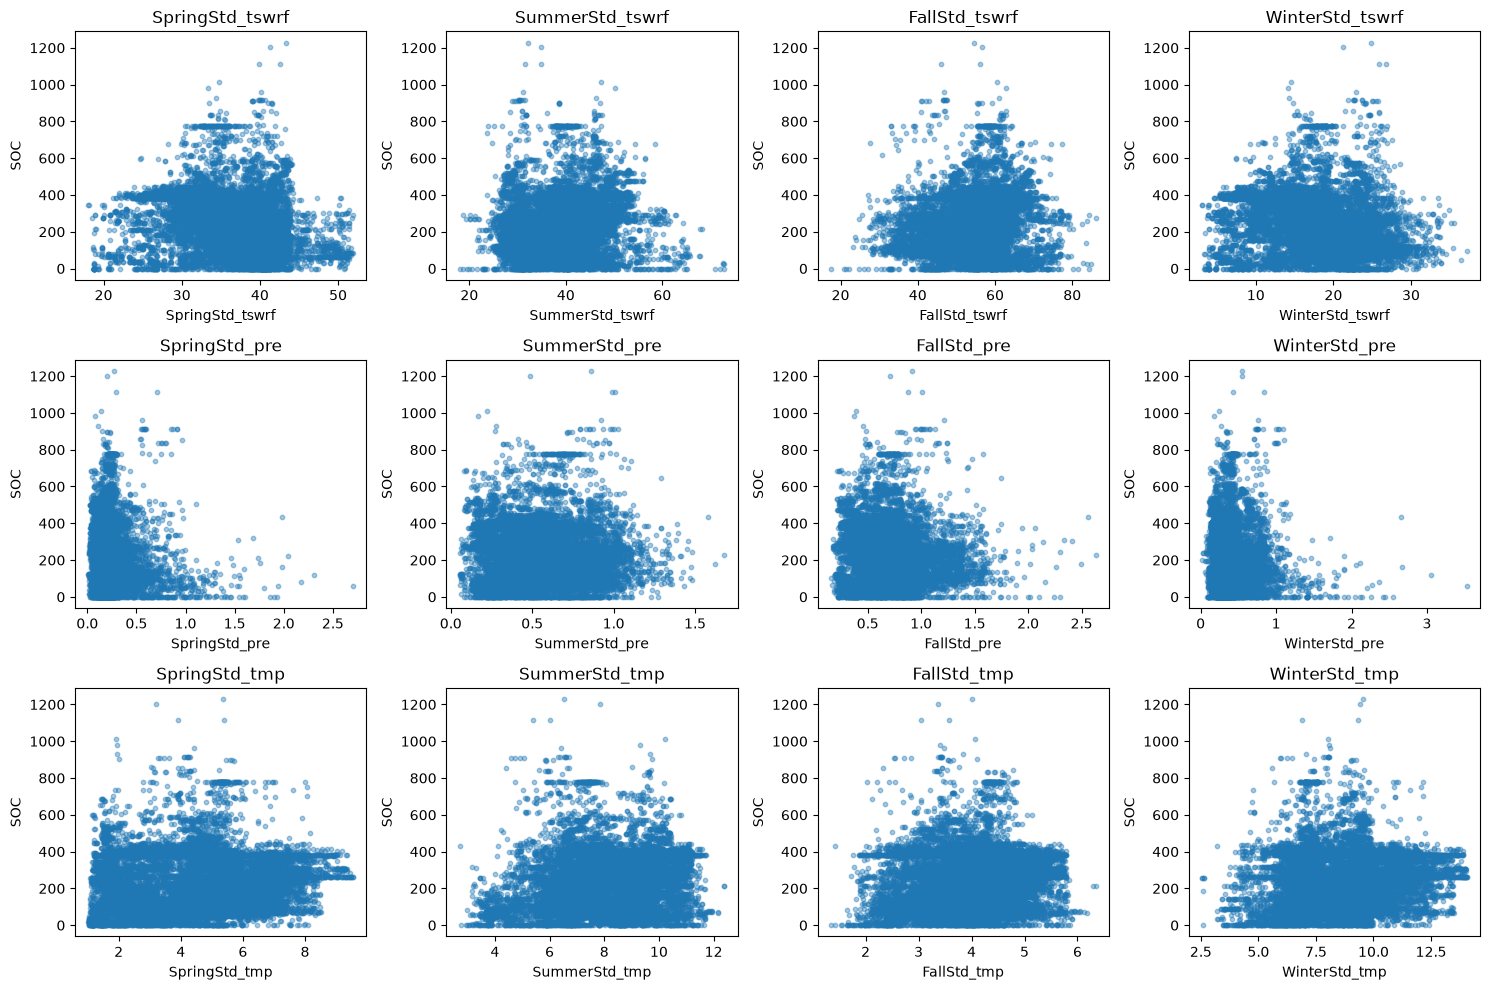

In [17]:
plot_cols = [col for col in merged_df.columns if any(f"Std_{var}" in col for var in ["tmp", "pre", "tswrf"])]

fig, axes = plt.subplots(3, (len(plot_cols) + 2) // 3, figsize=(15, 10))
for ax, col in zip(axes.flat, plot_cols):
    ax.scatter(merged_df[col], merged_df["NCSCD_SOCC100"], alpha=0.4, s=10)
    ax.set(xlabel=col, ylabel="SOC", title=col)
for ax in axes.flat[len(plot_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

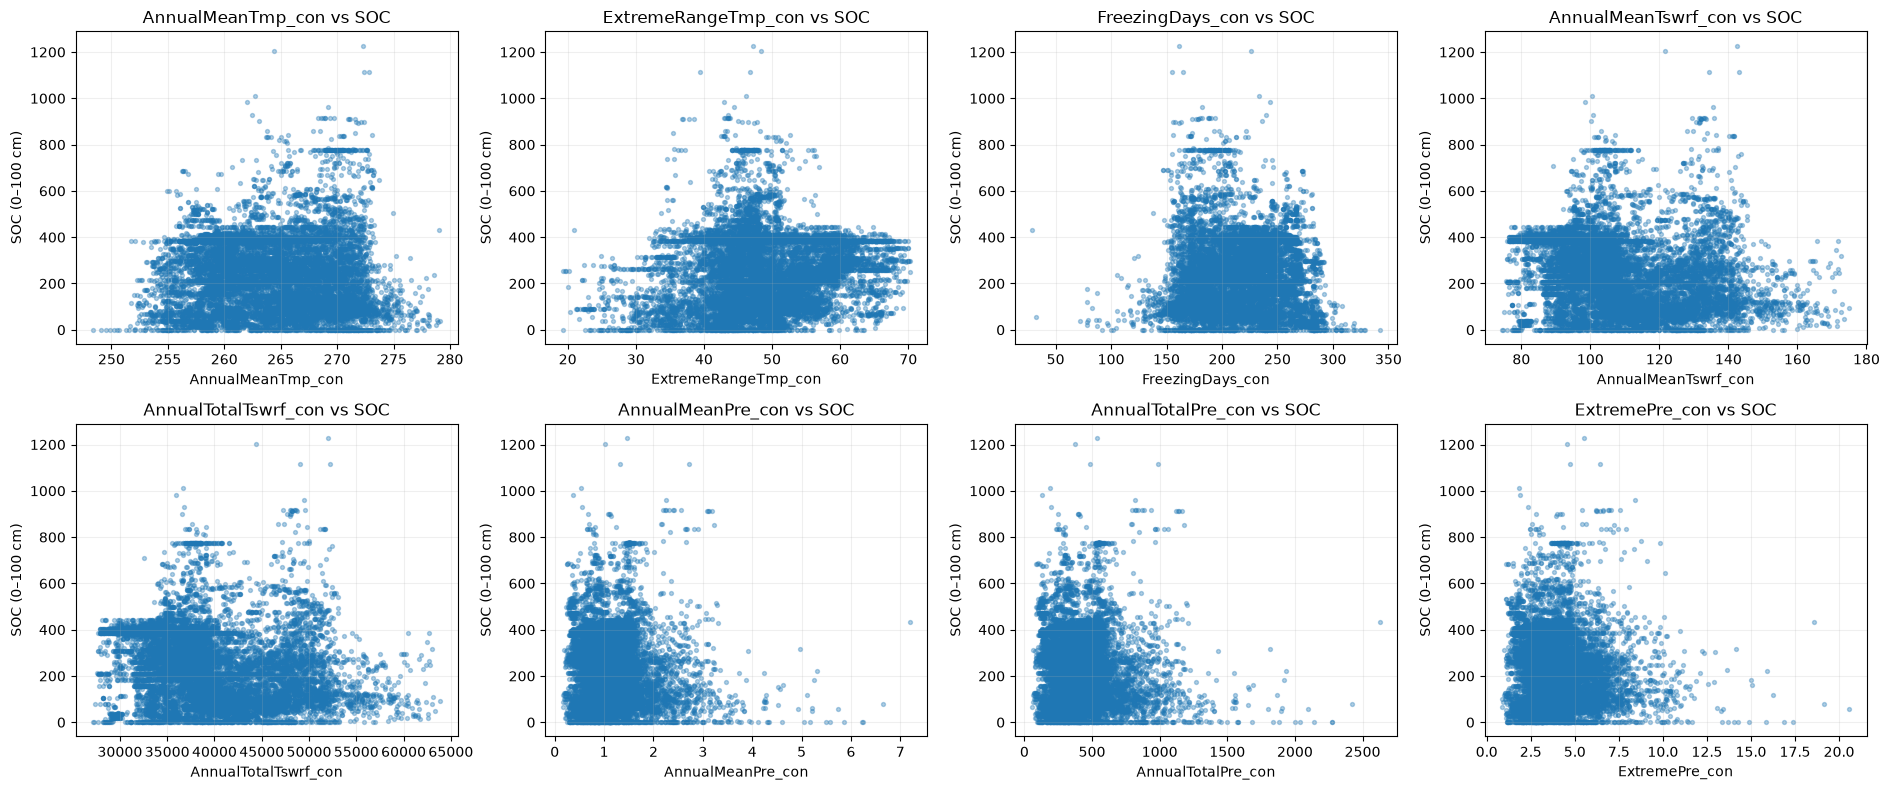

In [38]:
target = "NCSCD_SOCC100"
home_features = [
    "AnnualMeanTmp_con",
    "ExtremeRangeTmp_con",
    "FreezingDays_con",
    "AnnualMeanTswrf_con",
    "AnnualTotalTswrf_con",
    "AnnualMeanPre_con",
    "AnnualTotalPre_con",
    "ExtremePre_con"
]

ncols = 4
nrows = math.ceil(len(home_features) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(19, 4 * nrows))
axes = axes.flatten()

for ax, feature in zip(axes, home_features):
    ax.scatter(merged_df[feature], merged_df[target], alpha=0.35, s=8)
    ax.set(xlabel=feature, ylabel="SOC (0–100 cm)", title=f"{feature} vs SOC")
    ax.grid(alpha=0.2)

for ax in axes[len(home_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

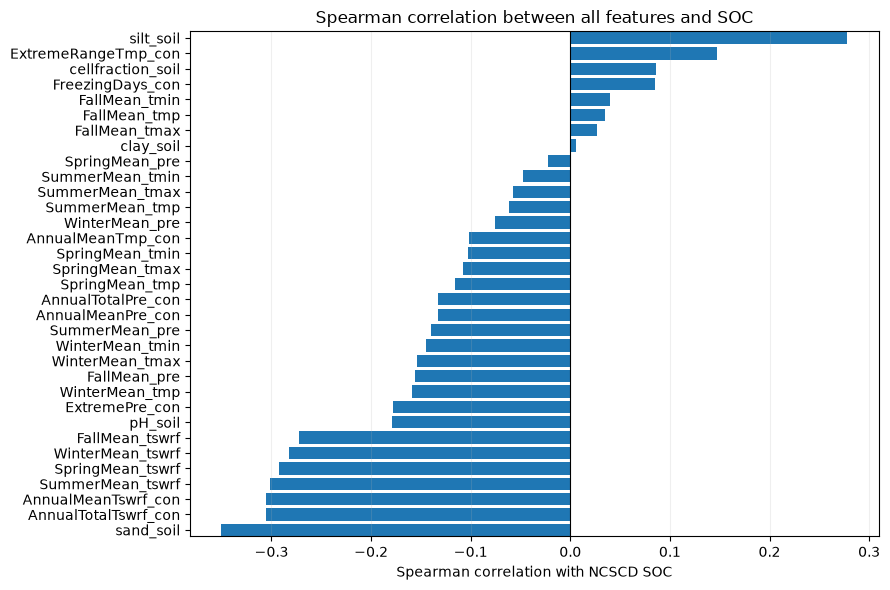

In [42]:
target = "NCSCD_SOCC100"
exclude = ["Lon", "Lat", target]
"""features = [col for col in merged_df.select_dtypes(include="number").columns if col not in exclude and not col.endswith("_grid") and not col.endswith("_lpj")]"""
features = [col for col in merged_df.select_dtypes(include="number").columns if col not in exclude and not col.endswith("_grid") and not col.endswith("_lpj")
            and "Std" not in col and "CN_soil" not in col and "orgC_soil" not in col and "Median" not in col and "nonsoil_pct" not in col]

results = []
for col in features:
    data = merged_df[[col, target]].dropna()
    if len(data) >= 3 and data[col].nunique() > 1 and data[target].nunique() > 1:
        results.append({"Feature": col, "Pearson": data[col].corr(data[target], method="pearson"), "Spearman": data[col].corr(data[target], method="spearman"), "N": len(data)})

corr_df = pd.DataFrame(results)
corr_df["Abs Pearson"] = corr_df["Pearson"].abs()
corr_df["Abs Spearman"] = corr_df["Spearman"].abs()
corr_df = corr_df.sort_values("Abs Spearman", ascending=False)
#print(corr_df[["Feature", "Pearson", "Spearman", "N"]].to_string(index=False))

top = corr_df.sort_values("Spearman")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["Feature"], top["Spearman"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Spearman correlation with NCSCD SOC", title="Spearman correlation between all features and SOC")
ax.grid(axis="x", alpha=0.2)
ax.margins(y=0.001)
plt.tight_layout()
plt.show()


## Neural Network

### Choose geographical section to use as test set
The aim is to select a test set that has around 10 % of the total dataset and a similar distribution of SOC to the rest of the dataset. 

/Users/andrearaaschou/courses/BERN02/.venv/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:301: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)


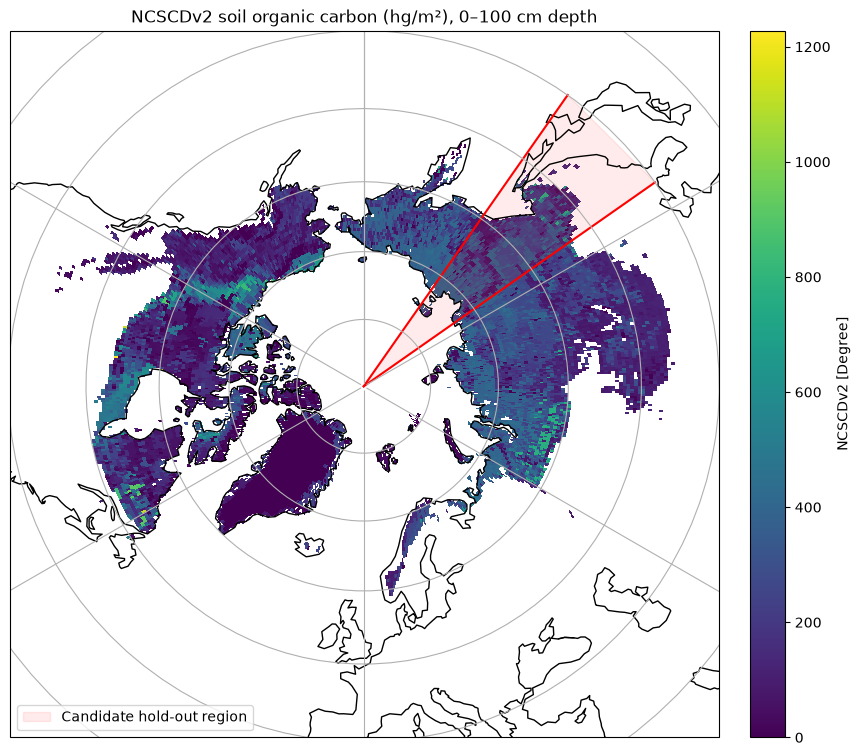

Total observations: 13,117
Test observations: 1,562 (11.91%)
Remaining observations: 11,555 (88.09%)


In [46]:
# Drop rows with nan values
merged_df = merged_df.dropna().reset_index(drop=True)

# Define test mask using coordinates from the cleaned DataFrame
center_lon = 135
sector_width = 20
min_lat = 40

lon = merged_df["Lon"]; lat = merged_df["Lat"]
lon_diff = ((lon - center_lon + 180) % 360) - 180
test_mask = (np.abs(lon_diff) <= sector_width / 2) & (lat >= min_lat)

# Make plot
lon_start = center_lon - sector_width / 2
lon_end = center_lon + sector_width / 2

cmap = plt.cm.viridis.copy()
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(10,10), subplot_kw={"projection": ccrs.NorthPolarStereo()})
soc.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, x="lon", y="lat", add_colorbar=True,
         cbar_kwargs={"shrink": 1, "fraction": 0.0456, "pad": 0.04})

ax.fill([lon_start, lon_start, lon_end, lon_end], # Overlay the pizza slice
        [min_lat, 90, 90, min_lat],
        transform=ccrs.PlateCarree(), color="red", alpha=0.08,
        label="Candidate hold-out region")

for lon_edge in [lon_start, lon_end]:  # Highlight the slice boundaries
    ax.plot([lon_edge, lon_edge], [min_lat, 90], transform=ccrs.PlateCarree(), color="red", linewidth=1.5)

ax.set_extent([-180, 180, 40, 90], crs=ccrs.PlateCarree())
ax.coastlines()
ax.gridlines()
ax.set_title("NCSCDv2 soil organic carbon (hg/m²), 0–100 cm depth")
ax.legend(loc="lower left")
plt.show()

# Calculate proportion of test set observations againt total number of observations
lon = merged_df["Lon"].to_numpy()
lat = merged_df["Lat"].to_numpy()
lon_diff = (lon - center_lon + 180) % 360 - 180 # Handle longitude wraparound at ±180°
n_total = len(merged_df)
n_test = test_mask.sum()
n_train = n_total - n_test
print(f"Total observations: {n_total:,}")
print(f"Test observations: {n_test:,} ({n_test / n_total:.2%})")
print(f"Remaining observations: {n_train:,} ({n_train / n_total:.2%})")

### Divide data into sets. TEST: remove outliers ± 3 sdt from mean

In [47]:
features = ["AnnualMeanTmp_con", "AnnualTotalPre_con", "FreezingDays_con", "ExtremePre_con", "AnnualTotalTswrf_con", "sand_soil", "silt_soil"]
target = "NCSCD_SOCC100"

# Remove missing values
merged_df = merged_df.dropna().copy()

X = merged_df[features].copy()
y = merged_df[target].copy()
weights = merged_df["weights"].copy()

# Separate spatial test region
X_region_train = X.loc[~test_mask]
y_region_train = y.loc[~test_mask]
w_region_train = weights.loc[~test_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]
w_test = weights.loc[test_mask]

# Split remaining region into training and validation sets
X_train, X_val, y_train, y_val, w_train, w_val = train_test_split(
    X_region_train, y_region_train, w_region_train,
    test_size=0.2, random_state=42
)

y_train_before = y_train.copy() # save for plotting later

# Remove outliers from training set only, using target values
col = target
mean, std = y_train.mean(), y_train.std()
lower, upper = mean - 3 * std, mean + 3 * std
train_mask = y_train.between(lower, upper)

print(f"Training rows before: {len(y_train)}")
print(f"Training rows removed: {(~train_mask).sum()}")

X_train = X_train.loc[train_mask]
y_train = y_train.loc[train_mask]
w_train = w_train.loc[train_mask]

print(f"Training rows remaining: {len(y_train)}")
print(f"Validation rows unchanged: {len(y_val)}")
print(f"Test rows unchanged: {len(y_test)}")

# Fit scaler on filtered training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("X train shape:", X_train.shape)
print("X val shape:", X_val.shape)
print("X test shape:", X_test.shape)
print("Predictors:", features)

Training rows before: 9244
Training rows removed: 120
Training rows remaining: 9124
Validation rows unchanged: 2311
Test rows unchanged: 1562
X train shape: (9124, 7)
X val shape: (2311, 7)
X test shape: (1562, 7)
Predictors: ['AnnualMeanTmp_con', 'AnnualTotalPre_con', 'FreezingDays_con', 'ExtremePre_con', 'AnnualTotalTswrf_con', 'sand_soil', 'silt_soil']


Training rows before: 9244
Training rows remaining: 9124
Training rows removed: 120


/var/folders/rb/jbpylnjd7n95gs7yp8cwggwc0000gn/T/ipykernel_13594/396695616.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box = axes[1].boxplot(


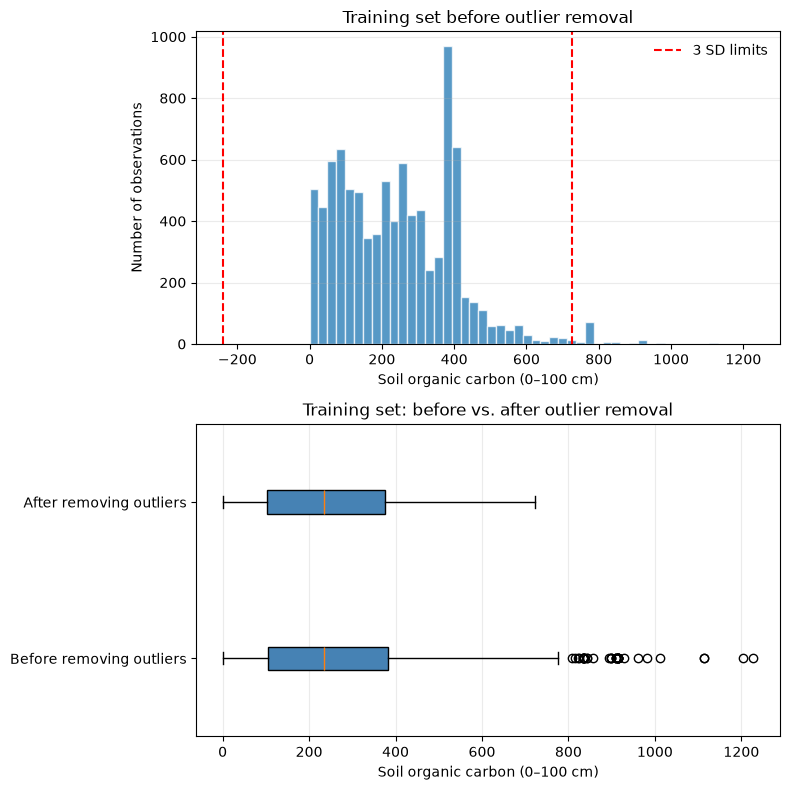

In [48]:
print(f"Training rows before: {len(y_train_before)}")
print(f"Training rows remaining: {len(y_train)}")
print(f"Training rows removed: {len(y_train_before) - len(y_train)}")

fig, axes = plt.subplots(2, 1, figsize=(8, 8))

# Histogram of the original training set
axes[0].hist(y_train_before, bins=50, alpha=0.75, edgecolor="white")
axes[0].axvline(lower, color="red", linestyle="--", linewidth=1.5, label="3 SD limits")
axes[0].axvline(upper, color="red", linestyle="--", linewidth=1.5)
axes[0].set_title("Training set before outlier removal")
axes[0].set_ylabel("Number of observations")
axes[0].set_xlabel("Soil organic carbon (0–100 cm)")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", alpha=0.25)

# Boxplots comparing training targets before and after filtering
box = axes[1].boxplot(
    [y_train_before, y_train],
    vert=False,
    patch_artist=True,
    tick_labels=["Before", "After"],
    showfliers=True
)
for patch in box["boxes"]:
    patch.set_facecolor("steelblue")

axes[1].set_title("Training set: before vs. after outlier removal")
axes[1].set_xlabel("Soil organic carbon (0–100 cm)")
axes[1].set_yticklabels(["Before removing outliers", "After removing outliers"])
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

### Build Neural Network

In [26]:
def build_nn(input_dim, hidden_layers=(16, 32, 32, 16), dropout = False, dropout_rate = 0.1, name="soc_model"):
    m = keras.Sequential(name=name)
    m.add(layers.Input(shape=(input_dim,))) # input layer

    for units in hidden_layers: # hidden layers
            m.add(layers.Dense(units, activation="relu"))
            if dropout:
                m.add(layers.Dropout(dropout_rate))

    m.add(layers.Dense(1, activation="relu")) # output layer
    m.compile(loss="mse", optimizer=keras.optimizers.Adam(), metrics=["mae"])
    return m

### Train

In [27]:
def train_model(hidden_layer = (64, 64, 32), dropout_rate = 0.2, weights = False, patience = 500, epochs = 3000):
    histories, models, results = {}, {}, {}

    for label, use_dropout in [("no dropout", False), ("dropout", True)]:
        keras.utils.set_random_seed(0)
        model = build_nn(
            input_dim=X_train.shape[1], 
            dropout=use_dropout,  
            dropout_rate=dropout_rate, 
            hidden_layers=hidden_layer, 
            name=label.replace(" ", "_"))
        
        early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
        fit_kwargs = {"batch_size": 50, 
                              "epochs": epochs, 
                              "validation_data": (X_val, y_val), 
                              "callbacks": [early_stop], 
                              "verbose": 0}
        if weights: # Add training weights to fit_kwargs
            fit_kwargs["sample_weight"] = w_train 
            
        history = model.fit(X_train, y_train, **fit_kwargs) # Fit model
        y_val_pred = model.predict(X_val, verbose=0).ravel() # Evaluate on the validation set
        results[label] = {
            "MAE": mean_absolute_error(y_val, y_val_pred),
            "MSE": mean_squared_error(y_val, y_val_pred),
            "R²": r2_score(y_val, y_val_pred)
        }
        histories[label], models[label] = history.history, model
        print(f"{label:11s}: stopped after {len(history.history['loss']):3d} epochs, "
            f"best val_loss {min(history.history['val_loss']):.2f}, "
            f"val MAE {results[label]['MAE']:.2f}, "
            f"val MSE {results[label]['MSE']:.2f}, "
            f"val R² {results[label]['R²']:.3f}")

        model.save(f"soc_nn_{label.replace(' ', '_')}.keras")
    return histories, models, results

### Evaluate

In [ ]:
# Plot training and validation loss (MAS) and MAE for any number of models.
def plot_training_history(histories):
    fig, ax = plt.subplots(1, 2, figsize=(11, 5))
    for label, h in histories.items():
        ep = np.arange(1, len(h["loss"]) + 1)
        ax[0].plot(ep, h["loss"], "--", label=f"{label}: train")
        ax[0].plot(ep, h["val_loss"], "-", label=f"{label}: validation")
        ax[1].plot(ep, h["mae"], "--", label=f"{label}: train")
        ax[1].plot(ep, h["val_mae"], "-", label=f"{label}: validation")
    ax[0].set(xlabel="Epoch", ylabel="MSE", ylim=(7000, 25000))
    ax[1].set(xlabel="Epoch", ylabel="MAE", ylim=(40, 160))
    for a in ax:
        a.legend(fontsize=8)
        a.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

# Plot observed vs predicted SOC
def plot_predictions(model, datasets, model_name="Neural network"):
    fig, axes = plt.subplots(1, len(datasets), figsize=(5 * len(datasets), 5), squeeze=False)
    predictions = {}
    for ax, (name, (X, y)) in zip(axes.ravel(), datasets.items()):
        y_obs = np.asarray(y).ravel()
        y_hat = model.predict(X, verbose=0).ravel()
        predictions[name] = y_hat
        ax.scatter(y_obs, y_hat, alpha=0.4, s=10)
        lims = [min(y_obs.min(), y_hat.min()), max(y_obs.max(), y_hat.max())]
        ax.plot(lims, lims, "r--")
        ax.set(xlabel="Observed SOC", ylabel="Predicted SOC", title=name)
        ax.grid(alpha=0.2)
    fig.suptitle(model_name)
    plt.tight_layout()
    plt.show()
    #return predictions

# Evaluate a model and inspect its errors. 
def evaluate_model(model, X, y, y_train, dataset_name="Validation set", n_groups=5, long = False):
    """This function calculates MSE, MAE, and R^2, compares the model against a baseline that always predicts the mean SOC of the training set, and returns diagnostics grouped by observed SOC."""
    y_obs = np.asarray(y).ravel()
    y_pred = model.predict(X, verbose=0).ravel()
    y_baseline = np.full(len(y_obs), np.mean(y_train))
    results = pd.DataFrame({
        "Model": [mean_squared_error(y_obs, y_pred), mean_absolute_error(y_obs, y_pred), r2_score(y_obs, y_pred)],
        "Mean baseline": [mean_squared_error(y_obs, y_baseline), mean_absolute_error(y_obs, y_baseline), r2_score(y_obs, y_baseline)]
    }, index=["MSE", "MAE", "R²"])
    diagnostics = pd.DataFrame({"observed": y_obs, "predicted": y_pred})
    diagnostics["error"] = diagnostics["predicted"] - diagnostics["observed"]
    diagnostics["SOC group"] = pd.qcut(diagnostics["observed"], q=n_groups, duplicates="drop")
    grouped = diagnostics.groupby("SOC group", observed=True)[["observed", "predicted", "error"]].mean().round(2)
    summary = pd.DataFrame({
        "Observed": [np.mean(y_obs), np.std(y_obs), np.min(y_obs), np.max(y_obs)],
        "Predicted": [np.mean(y_pred), np.std(y_pred), np.min(y_pred), np.max(y_pred)]
    }, index=["Mean", "Std deviation", "Minimum", "Maximum"])
    print(f"\n{dataset_name} — model vs baseline")
    print(results.round(4))
    if long: 
        print("\nMean values by observed SOC group:")
        print(grouped)
        print("\nObserved vs predicted summary:")
        print(summary.round(2))
    #return {"metrics": results, "diagnostics": diagnostics, "grouped": grouped, "summary": summary, "predictions": y_pred}

### Run functions

In [51]:
histories, models, results = train_model(
    hidden_layer = (64, 64, 32), 
    dropout_rate = 0.2, 
    weights = True, 
    patience = 1000, 
    epochs = 5000) 

no dropout : stopped after 3604 epochs, best val_loss 14435.69, val MAE 80.68, val MSE 14435.69, val R² 0.448
dropout    : stopped after 4305 epochs, best val_loss 13903.41, val MAE 81.86, val MSE 13903.41, val R² 0.468


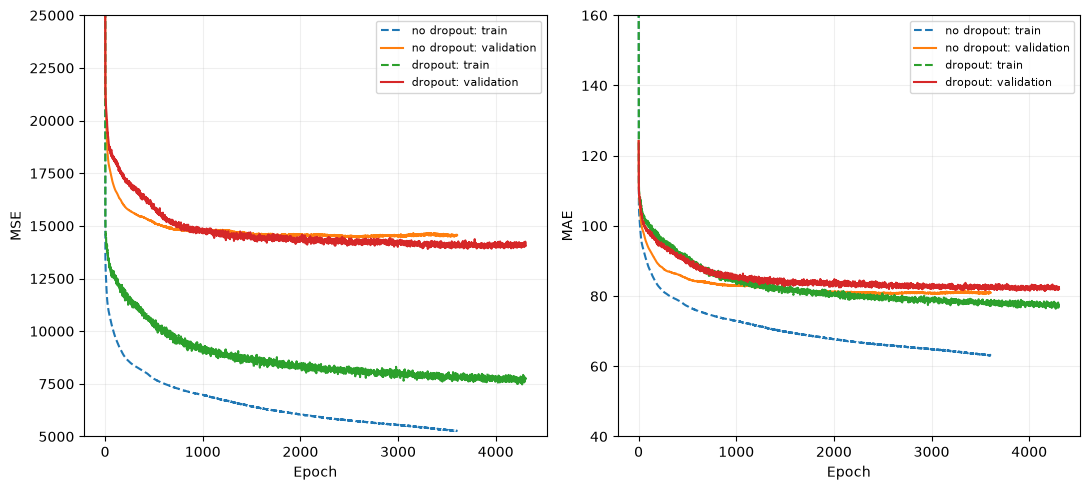

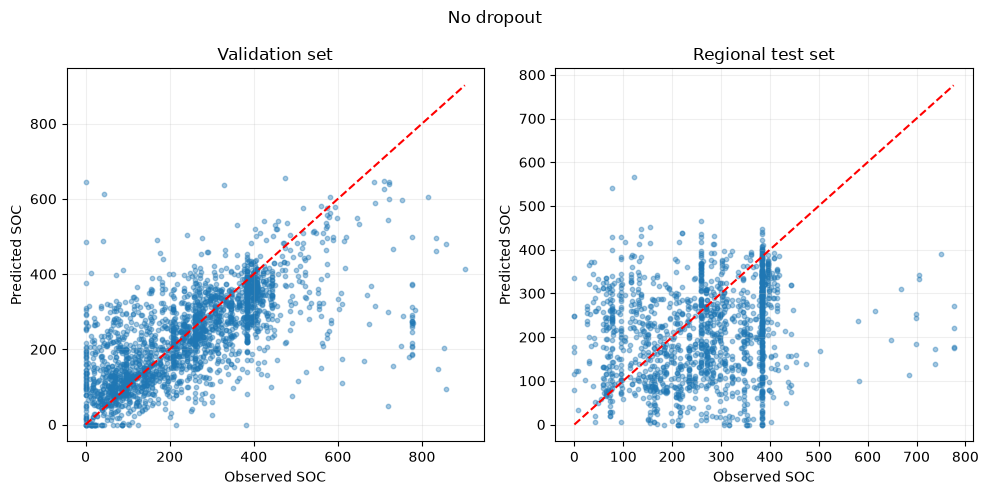

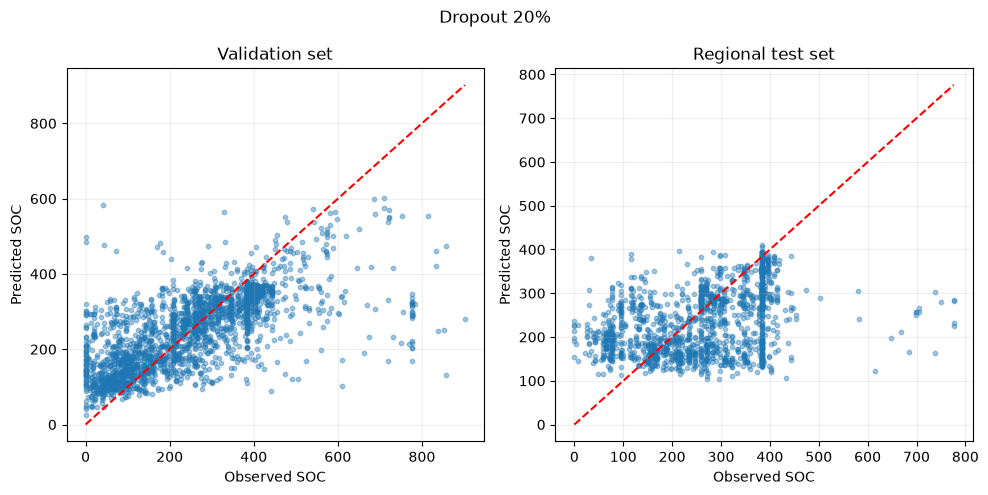


Validation set — model vs baseline
          Model  Mean baseline
MSE  14435.6924     26355.1680
MAE     80.6824       131.7431
R²       0.4475        -0.0087

Validation set — model vs baseline
          Model  Mean baseline
MSE  13903.4092     26355.1680
MAE     81.8621       131.7431
R²       0.4679        -0.0087

Regional test set — model vs baseline
          Model  Mean baseline
MSE  14215.2998     15541.3281
MAE     89.8853       103.4627
R²       0.0350        -0.0550


In [ ]:
plot_training_history(histories)
plot_predictions(models["no dropout"], {"Validation set": (X_val, y_val), "Regional test set": (X_test, y_test)}, model_name="No dropout")
plot_predictions(models["dropout"], {"Validation set": (X_val, y_val), "Regional test set": (X_test, y_test)}, model_name="Dropout 20%") 
evaluate_model(models["no dropout"], X_val, y_val, y_train, "Validation set")
evaluate_model(models["dropout"], X_val, y_val, y_train, "Validation set")
#evaluate_model(models["dropout"], X_test, y_test, y_train, "Regional test set")

### Evaluate on test set

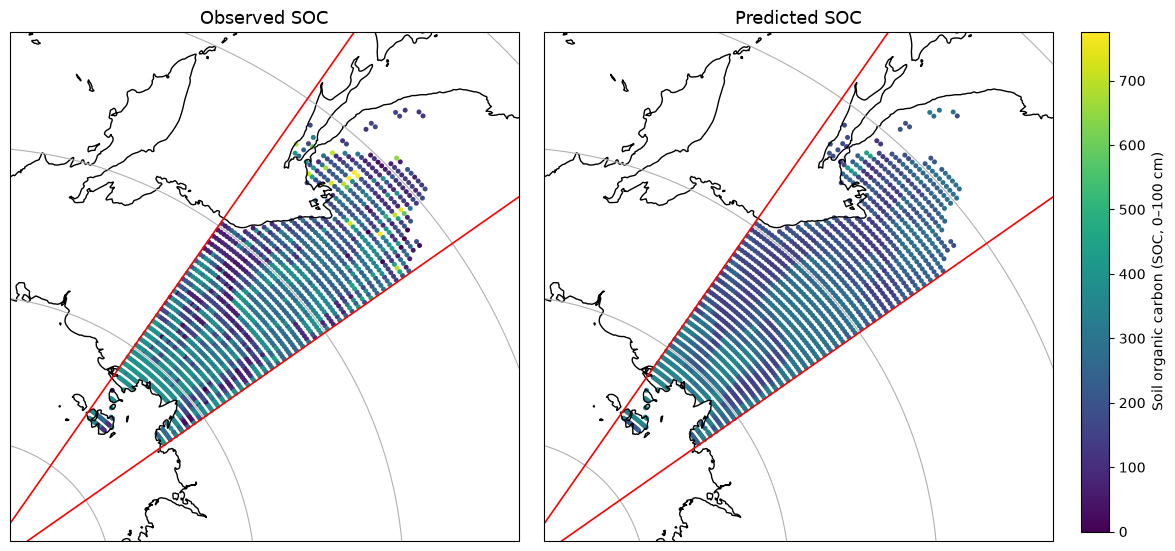

In [ ]:
def plot_regional_soc_map(model, merged_df, test_mask, lon_start, lon_end, min_lat, target="NCSCD_SOCC100"):
    test_data = merged_df.loc[test_mask].copy()
    y_test_actual = test_data[target].to_numpy()
    y_test_pred = model.predict(X_test, verbose=0).ravel()

    assert len(test_data) == len(y_test_pred), "Test coordinates and predictions have different lengths"

    lon_test, lat_test = test_data["Lon"].to_numpy(), test_data["Lat"].to_numpy()
    vmin, vmax = 0, np.nanmax(y_test_actual)

    proj = ccrs.NorthPolarStereo()
    fig, axes = plt.subplots(1, 2, figsize=(14, 10), subplot_kw={"projection": proj})
    plots = [(axes[0], y_test_actual, "Observed SOC"), (axes[1], y_test_pred, "Predicted SOC")]

    for ax, values, title in plots:
        sc = ax.scatter(lon_test, lat_test, c=values, transform=ccrs.PlateCarree(),
                        cmap="viridis", vmin=vmin, vmax=vmax, s=13, linewidths=0)
        ax.set_extent([lon_start, lon_end, min_lat + 5, 85], crs=ccrs.PlateCarree())
        ax.coastlines()
        gl = ax.gridlines(draw_labels=False)
        gl.xlines = False
        ax.set_title(title, fontsize=13)
        for lon_edge in [lon_start, lon_end]:
            ax.plot([lon_edge, lon_edge], [min_lat + 5, 85],
                    transform=ccrs.PlateCarree(), color="red", linewidth=1.2)

    fig.subplots_adjust(right=0.87, wspace=0.05)
    cbar_ax = fig.add_axes([0.89, 0.25, 0.02, 0.5])
    fig.colorbar(sc, cax=cbar_ax, label="Soil organic carbon (SOC, 0–100 cm)")
    plt.show()

    return pd.DataFrame({"Lon": lon_test, "Lat": lat_test, "Observed_SOC": y_test_actual, "Predicted_SOC": y_test_pred})

test_predictions = plot_regional_soc_map(
    model=models["dropout"],
    merged_df=merged_df,
    test_mask=test_mask,
    lon_start=lon_start,
    lon_end=lon_end,
    min_lat=min_lat
)